In [1]:
from google.colab import drive
drive.mount('/content/drive')

# **mit bih arrhythmia data analysis**

In [ ]:
pip install wfdb


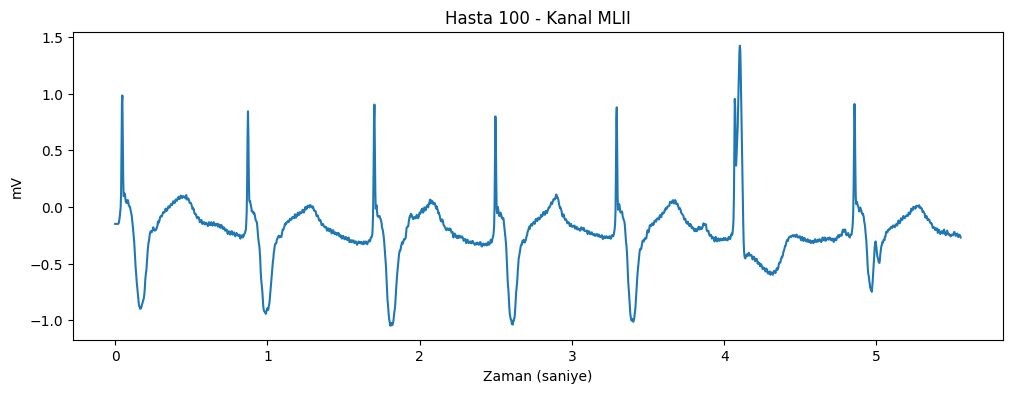

In [ ]:
sig = record.p_signal  # sinyalin numpy array hali (örnek x kanal)
fs = record.fs         # örnekleme frekansı (360 Hz)

time = [i/fs for i in range(len(sig))]  # zaman ekseni

plt.figure(figsize=(12,4))
plt.plot(time[:2000], sig[:2000,0])  # 2000 örnek = 5.5 sn, 0. kanal (MLII)
plt.title("Hasta 100 - Kanal MLII")
plt.xlabel("Zaman (saniye)")
plt.ylabel("mV")
plt.show()


In [ ]:
# -*- coding: utf-8 -*-
# MIT-BIH: Her hasta için 2 çıktı PNG (ekg.png + params.png)
# pip install wfdb numpy scipy matplotlib

import os, glob, math, warnings
import numpy as np
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt

# ================== KULLANICI AYARLARI ==================
PN_DIR = "mitdb"            # Yerel klasör yolu ya da "mitdb"
OUT_ROOT = "patients"       # Çıktıların üst klasörü
WINDOW_SEC = 8              # EKG görsel penceresi (s)
USE_ONLY_NORMAL_FOR_PARAMS = False  # True: sadece 'N' beat'lerinden metrik hesapla
# ========================================================

warnings.simplefilter("ignore", category=UserWarning)

# ---------- Yardımcılar ----------
def bandpass_ecg(x, fs, low=0.5, high=40.0, order=3):
    """
    EKG sinyalini bant geçiren filtreden geçirir.
    - Düşük frekans (drift, hareket artefaktı) ve yüksek frekans (gürültü/EMG) bileşenlerini bastırır.
    - Klinik cihazlarda tipik kullanılan 0.5–40 Hz bandı uygulanır.
    """
    b, a = butter(order, [low/(fs/2.0), high/(fs/2.0)], btype='bandpass')
    return filtfilt(b, a, x)

def discover_records(pn_dir):
    """
    Kayıt listesini bulur.
    - Önce yerel klasördeki .hea dosyalarına bakar.
    - Yoksa PhysioNet’ten (mitdb) kayıt listesini çeker.
    - İkisi de olmazsa bilinen kayıtların sabit bir listesini döndürür.
    """
    # Yerel .hea’lardan bul
    if os.path.isdir(pn_dir):
        heas = glob.glob(os.path.join(pn_dir, "*.hea"))
        recs = sorted({os.path.splitext(os.path.basename(h))[0] for h in heas})
        recs = [r for r in recs if r.split("-")[0].isdigit()]
        if recs:
            return recs
    # PhysioNet listesi
    try:
        return wfdb.get_record_list('mitdb')
    except Exception:
        return [str(x) for x in
                [100,101,102,103,104,105,106,107,108,109,
                 111,112,113,114,115,116,117,118,119,
                 121,122,123,124,200,201,202,203,205,207,
                 208,209,210,212,213,214,215,217,219,220,
                 221,222,223,228,230,231,232,233,234]]

def pick_normal_window(ann, fs, total_samples, window_sec=8):
    """
    'N' (normal beat) etrafında window_sec saniyelik bir pencere seçer.
    - Uygun pencerede aritmi varsa atlar.
    - Bulamazsa kaydın ortasından bir pencere döndürür.
    """
    half_w = int((window_sec * fs) // 2)
    idxs = [i for i, s in enumerate(ann.symbol) if s == 'N']
    for i in idxs:
        center = ann.sample[i]
        if center - half_w < 0 or center + half_w > total_samples:
            continue
        start, end = int(center - half_w), int(center + half_w)
        # pencere içinde ağır aritmi varsa es geç (basit kural)
        in_win = np.where((ann.sample >= start) & (ann.sample <= end))[0]
        syms = [ann.symbol[k] for k in in_win]
        if any(len(s) == 1 and s != 'N' for s in syms):
            continue
        return start, end
    # Olmazsa kaydın ortasından ver
    mid = total_samples // 2
    return max(0, mid - half_w), min(total_samples, mid + half_w)

def rr_intervals_from_annotations(ann, fs, only_normal=False):
    """
    Annotation’daki atım işaretlerinden (R konumları) RR aralıklarını (s) çıkarır.
    - only_normal=True ise sadece 'N' beat’leri kullanılır.
    - Fizyolojik olmayan değerler (0.3–2.5 s) ayıklanır.
    """
    beat_mask = np.array([len(s) == 1 and s.isalpha() for s in ann.symbol])
    if only_normal:
        beat_mask &= (np.array(ann.symbol) == 'N')
    rpos = np.array(ann.sample)[beat_mask]
    if len(rpos) < 2:
        return np.array([])
    rr = np.diff(rpos) / fs
    rr = rr[(rr >= 0.3) & (rr <= 2.5)]
    return rr

def estimate_qrs_width(signal, fs, r_indices, search_ms=120):
    """
    QRS kompleks genişliğini (s) tahmin eder.
    - R etrafında ±search_ms pencerede türev/slope analizi yapar.
    - QRS başlangıç ve bitişini bulup süreyi hesaplar; median döndürür.
    - Tipik QRS: 70–110 ms.
    """
    if len(r_indices) == 0:
        return np.nan
    w = int(search_ms * fs / 1000.0)
    deriv = np.diff(signal, prepend=signal[0]) * fs
    widths = []
    for r in r_indices:
        a, b = max(0, r - w), min(len(signal) - 1, r + w)
        local = deriv[a:b]
        thr = 0.25 * np.nanmax(np.abs(local)) if np.nanmax(np.abs(local)) > 0 else 0
        if thr == 0:
            continue
        # sola bak (QRS onset)
        onset = r
        for i in range(r, a, -1):
            if abs(deriv[i]) < 0.2 * thr:
                onset = i
                break
        # sağa bak (QRS offset)
        offset = r
        for i in range(r, b):
            if abs(deriv[i]) < 0.2 * thr:
                offset = i
                break
        dur = (offset - onset) / fs
        if 0.04 <= dur <= 0.20:  # 40–200 ms aralığına kısıt
            widths.append(dur)
    if len(widths) == 0:
        return np.nan
    return float(np.nanmedian(widths))

def estimate_pr_interval(signal, fs, r_indices, qrs_onsets, search_ms=200):
    """
    PR intervalini (s) tahmin eder.
    - QRS başlangıcından geriye ±search_ms pencerede P başlangıcını arar.
    - Atriyumdan ventriküle iletim süresini verir; median döner.
    - Tipik PR: 120–200 ms.
    """
    if len(r_indices) == 0 or len(qrs_onsets) == 0:
        return np.nan
    deriv = np.diff(signal, prepend=signal[0]) * fs
    pr_list = []
    back = int(search_ms * fs / 1000.0)
    for r, q_on in zip(r_indices, qrs_onsets):
        a = max(0, q_on - back)
        local = deriv[a:q_on]
        if len(local) < 5:
            continue
        thr = 0.20 * np.nanmax(np.abs(local)) if np.nanmax(np.abs(local)) > 0 else 0
        # P onset: düşük slope zonundan önceki ilk belirgin slope
        p_on = q_on
        for i in range(q_on - 1, a, -1):
            if abs(deriv[i]) < 0.2 * thr:
                p_on = i
                break
        pr = (q_on - p_on) / fs
        if 0.08 <= pr <= 0.32:   # 80–320 ms
            pr_list.append(pr)
    if len(pr_list) == 0:
        return np.nan
    return float(np.nanmedian(pr_list))

def estimate_qt_interval(signal, fs, r_indices, qrs_onsets, search_ms=600):
    """
    QT intervalini (s) tahmin eder.
    - QRS başlangıcından itibaren T bitimini bulur (türevin düşük kaldığı bölge).
    - Ventrikül depolarizasyonu + repolarizasyonu toplam süresidir; median döner.
    - Tipik QT: ~350–440 ms; hıza göre düzeltilmiş QTc kullanılır.
    """
    deriv = np.diff(signal, prepend=signal[0]) * fs
    qt_list = []
    fwd = int(search_ms * fs / 1000.0)
    for r, q_on in zip(r_indices, qrs_onsets):
        a = q_on
        b = min(len(signal) - 1, q_on + fwd)
        local = deriv[a:b]
        if len(local) < 10:
            continue
        thr = 0.15 * np.nanmax(np.abs(local)) if np.nanmax(np.abs(local)) > 0 else 0
        t_off = b
        # türev uzun süre küçük kalınca T bitti varsay
        win = int(0.04 * fs)  # 40 ms pencere
        for i in range(a + win, b):
            seg = np.abs(deriv[i - win:i])
            if np.nanmax(seg) < thr:
                t_off = i
                break
        qt = (t_off - q_on) / fs
        if 0.24 <= qt <= 0.60:   # 240–600 ms tipik aralık
            qt_list.append(qt)
    if len(qt_list) == 0:
        return np.nan
    return float(np.nanmedian(qt_list))

def qrs_onsets_offsets(signal, fs, r_indices, search_ms=120):
    """
    QRS komplekslerinin başlangıç (onset) ve bitiş (offset) indekslerini döndürür.
    - R tepe etrafında ±search_ms pencerede slope analizi yapar.
    """
    w = int(search_ms * fs / 1000.0)
    deriv = np.diff(signal, prepend=signal[0]) * fs
    onsets, offsets = [], []
    for r in r_indices:
        a, b = max(0, r - w), min(len(signal) - 1, r + w)
        local = deriv[a:b]
        thr = 0.25 * np.nanmax(np.abs(local)) if np.nanmax(np.abs(local)) > 0 else 0
        if thr == 0:
            onsets.append(r); offsets.append(r); continue
        onset = r
        for i in range(r, a, -1):
            if abs(deriv[i]) < 0.2 * thr:
                onset = i; break
        offset = r
        for i in range(r, b):
            if abs(deriv[i]) < 0.2 * thr:
                offset = i; break
        onsets.append(onset); offsets.append(offset)
    return onsets, offsets

def make_dirs(path):
    """
    Klasör oluşturur (varsa hata vermez).
    - Her hasta için ayrı klasör yaratmakta kullanılır.
    """
    os.makedirs(path, exist_ok=True)

# ---------- Çizimler ----------
def plot_ekg_window(rec, ann, start, end, out_png):
    """
    Verilen kayıt ve zaman aralığından EKG penceresi çizer ve kaydeder.
    - İki kanal ayrı subplotlarda gösterilir.
    - Annotation (beat noktaları) üstte küçük işaretlerle gösterilir.
    """
    fs = rec.fs
    t = np.arange(start, end) / fs
    seg = rec.p_signal[start:end, :]
    leads = rec.sig_name
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    fig.suptitle(f"Hasta {rec.record_name} – MIT-BIH (Normal pencere, ~{(end-start)/fs:.1f}s)")
    axes[0].plot(t, seg[:, 0]); axes[0].set_ylabel(f"{leads[0]} (mV)"); axes[0].grid(True, alpha=.3)
    if seg.shape[1] > 1:
        axes[1].plot(t, seg[:, 1]); axes[1].set_ylabel(f"{leads[1]} (mV)"); axes[1].grid(True, alpha=.3)
    else:
        axes[1].axis('off')
    in_win = np.where((ann.sample >= start) & (ann.sample <= end))[0]
    marks = (ann.sample[in_win] - start) / fs + t[0]
    colors = ['C3','C2','C1','C4','C5','C6','C7','C8']
    for ax in axes:
        y = ax.get_ylim()[1] * 0.92
        for i, tt in enumerate(marks):
            ax.plot([tt], [y], marker='v', markersize=6, color=colors[i % len(colors)])
    axes[-1].set_xlabel("Zaman (s)")
    plt.tight_layout()
    plt.savefig(out_png, dpi=150); plt.close(fig)

def plot_params_png(rec_id, params, out_png):
    """
    Hesaplanan parametreleri (HR, RR, QRS, PR, QT, QTc) özet halinde PNG’ye yazar.
    - Başlık (üstte) ve metin bloğu (hemen altında) çakışmayacak şekilde konumlandırılır.
    """
    lines = [
        f"Hasta: {rec_id}",
        "",
        f"Ventrikül Hızı (bpm):   ort={params['hr_mean']:.1f}   medyan={params['hr_median']:.1f}   min={params['hr_min']:.1f}   max={params['hr_max']:.1f}",
        f"RR interval (s):        ort={params['rr_mean']:.3f}   sd={params['rr_sd']:.3f}",
        "",
        f"QRS Süresi (ms):        ~{params['qrs_ms']:.0f}" if not math.isnan(params['qrs_ms']) else "QRS Süresi:          ölçülemedi",
        f"PR İntervali (ms):      ~{params['pr_ms']:.0f}"  if not math.isnan(params['pr_ms'])  else "PR İntervali:        ölçülemedi",
        f"QT İntervali (ms):      ~{params['qt_ms']:.0f}"  if not math.isnan(params['qt_ms'])  else "QT İntervali:        ölçülemedi",
    ]
    if not math.isnan(params.get('qtc_ms', np.nan)):
        lines.append(f"QTc (Bazett) (ms):      ~{params['qtc_ms']:.0f}")

    fig = plt.figure(figsize=(10, 6))
    plt.axis('off')

    # Başlık
    plt.text(0.02, 0.95, "MIT-BIH Parametre Özeti",
             fontsize=16, fontweight='bold', va='top')

    # Metin bloğu
    plt.text(0.02, 0.85, "\n".join(lines),
             fontsize=13, family='monospace', va='top')

    plt.savefig(out_png, dpi=150, bbox_inches='tight')
    plt.close(fig)

# ---------- Ana hesaplayıcı ----------
def process_record(rec_id):
    """
    Tek kayıt (hasta) için akış:
      1) Kayıt ve anotasyonu yükle
      2) Normal pencere seç ve ekg.png üret
      3) RR ve HR hesapla
      4) QRS/PR/QT ve QTc tahmin et
      5) params.png olarak yaz
    """
    try:
        rec = wfdb.rdrecord(str(rec_id), pn_dir=PN_DIR)
        ann = wfdb.rdann(str(rec_id), 'atr', pn_dir=PN_DIR)
    except Exception as e:
        print(f"[{rec_id}] okunamadı: {e}")
        return

    fs = int(rec.fs)
    sig = rec.p_signal[:, 0]  # Heuristikler 1. kanalda (genelde MLII)
    sig_f = bandpass_ecg(sig, fs)

    # 1) Pencere seç ve ekg.png
    s, e = pick_normal_window(ann, fs, rec.sig_len, WINDOW_SEC)
    out_dir = os.path.join(OUT_ROOT, str(rec_id))
    make_dirs(out_dir)
    plot_ekg_window(rec, ann, s, e, os.path.join(out_dir, "ekg.png"))

    # 2) RR & HR
    rr = rr_intervals_from_annotations(ann, fs, only_normal=USE_ONLY_NORMAL_FOR_PARAMS)
    if len(rr) == 0:
        rr = np.array([np.nan])
    hr = 60.0 / rr
    hr = hr[~np.isnan(hr)]

    # 3) QRS, PR, QT (heuristik)
    beat_mask = np.array([len(s) == 1 and s.isalpha() for s in ann.symbol])
    if USE_ONLY_NORMAL_FOR_PARAMS:
        beat_mask &= (np.array(ann.symbol) == 'N')
    rpos = np.array(ann.sample)[beat_mask]

    q_on, q_off = qrs_onsets_offsets(sig_f, fs, rpos)
    qrs_sec = estimate_qrs_width(sig_f, fs, rpos)
    pr_sec  = estimate_pr_interval(sig_f, fs, rpos, q_on)
    qt_sec  = estimate_qt_interval(sig_f, fs, rpos, q_on)

    # QTc (Bazett): QTc = QT / sqrt(RR_mean)
    qtc_ms = np.nan
    if not math.isnan(qt_sec) and np.isfinite(np.nanmean(rr)):
        qtc_ms = 1000.0 * qt_sec / math.sqrt(np.nanmean(rr))

    params = {
        "hr_mean": float(np.nanmean(hr)) if len(hr) else np.nan,
        "hr_median": float(np.nanmedian(hr)) if len(hr) else np.nan,
        "hr_min": float(np.nanmin(hr)) if len(hr) else np.nan,
        "hr_max": float(np.nanmax(hr)) if len(hr) else np.nan,
        "rr_mean": float(np.nanmean(rr)),
        "rr_sd": float(np.nanstd(rr, ddof=1)) if len(rr) > 1 else 0.0,
        "qrs_ms": 1000.0 * qrs_sec if not math.isnan(qrs_sec) else np.nan,
        "pr_ms":  1000.0 * pr_sec  if not math.isnan(pr_sec)  else np.nan,
        "qt_ms":  1000.0 * qt_sec  if not math.isnan(qt_sec)  else np.nan,
        "qtc_ms": qtc_ms
    }

    # 4) params.png
    plot_params_png(rec_id, params, os.path.join(out_dir, "params.png"))
    print(f"[{rec_id}] ✓ ekg.png ve params.png üretildi.")



In [ ]:
def main():
    """
    Tüm kayıtları sırayla işler ve çıktılarını patients/<ID>/ içine kaydeder.
    """
    recs = discover_records(PN_DIR)
    print(f"{len(recs)} kayıt bulundu.")
    os.makedirs(OUT_ROOT, exist_ok=True)
    for rid in recs:
        process_record(rid)

if __name__ == "__main__":
    main()


48 kayıt bulundu.
[100] ✓ ekg.png ve params.png üretildi.
[101] ✓ ekg.png ve params.png üretildi.
[102] ✓ ekg.png ve params.png üretildi.
[103] ✓ ekg.png ve params.png üretildi.
[104] ✓ ekg.png ve params.png üretildi.
[105] ✓ ekg.png ve params.png üretildi.
[106] ✓ ekg.png ve params.png üretildi.
[107] ✓ ekg.png ve params.png üretildi.
[108] ✓ ekg.png ve params.png üretildi.
[109] ✓ ekg.png ve params.png üretildi.
[111] ✓ ekg.png ve params.png üretildi.
[112] ✓ ekg.png ve params.png üretildi.
[113] ✓ ekg.png ve params.png üretildi.
[114] ✓ ekg.png ve params.png üretildi.
[115] ✓ ekg.png ve params.png üretildi.
[116] ✓ ekg.png ve params.png üretildi.
[117] ✓ ekg.png ve params.png üretildi.
[118] ✓ ekg.png ve params.png üretildi.
[119] ✓ ekg.png ve params.png üretildi.
[121] ✓ ekg.png ve params.png üretildi.
[122] ✓ ekg.png ve params.png üretildi.
[123] ✓ ekg.png ve params.png üretildi.
[124] ✓ ekg.png ve params.png üretildi.
[200] ✓ ekg.png ve params.png üretildi.
[201] ✓ ekg.png ve par

In [ ]:
!zip -r mit-bih-arrhythmia-database-patients_analysis.zip /content/patients

In [ ]:
import shutil
shutil.copy("/content/mit-bih-arrhythmia-database-patients_analysis.zip","/content/drive/MyDrive/Cormetry")

'/content/drive/MyDrive/Cormetry'

#**data visualization**

In [ ]:
!unzip "/content/drive/MyDrive/Cormetry /mit-bih-arrhythmia-database-patients_analysis.zip"

In [ ]:
# -*- coding: utf-8 -*-
# MIT-BIH: Her kayıt için 5 çıktı (ekg.png, params.png, signal.csv, annotations.csv, meta.json)
# pip install wfdb numpy scipy matplotlib

import os, glob, math, warnings, json
import numpy as np
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt

# ================== KULLANICI AYARLARI ==================
PN_DIR = "mitdb"            # Yerel klasör yolu ya da "mitdb"
OUT_ROOT = "patients"       # Tüm çıktıların kök klasörü
WINDOW_SEC = 8              # EKG görsel penceresi (s)
USE_ONLY_NORMAL_FOR_PARAMS = False  # True: sadece 'N' beat'lerinden metrik hesapla
SAVE_FLOAT_FMT = "%.6f"     # CSV sayı formatı
# ========================================================

warnings.simplefilter("ignore", category=UserWarning)

# ---------- Yardımcılar ----------
def bandpass_ecg(x, fs, low=0.5, high=40.0, order=3):
    """
    EKG sinyalini bant geçiren filtreden geçirir.
    - Düşük frekans (drift, hareket artefaktı) ve yüksek frekans (gürültü/EMG) bileşenlerini bastırır.
    - Klinik cihazlarda tipik kullanılan 0.5–40 Hz bandı uygulanır.
    """
    b, a = butter(order, [low/(fs/2.0), high/(fs/2.0)], btype='bandpass')
    return filtfilt(b, a, x)

def discover_records(pn_dir):
    """
    Kayıt listesini bulur.
    - Önce yerel klasördeki .hea dosyalarına bakar.
    - Yoksa PhysioNet’ten (mitdb) kayıt listesini çeker.
    - İkisi de olmazsa bilinen kayıtların sabit bir listesini döndürür.
    """
    if os.path.isdir(pn_dir):
        heas = glob.glob(os.path.join(pn_dir, "*.hea"))
        recs = sorted({os.path.splitext(os.path.basename(h))[0] for h in heas})
        recs = [r for r in recs if r.split("-")[0].isdigit()]
        if recs:
            return recs
    try:
        return wfdb.get_record_list('mitdb')
    except Exception:
        return [str(x) for x in
                [100,101,102,103,104,105,106,107,108,109,
                 111,112,113,114,115,116,117,118,119,
                 121,122,123,124,200,201,202,203,205,207,
                 208,209,210,212,213,214,215,217,219,220,
                 221,222,223,228,230,231,232,233,234]]

def pick_normal_window(ann, fs, total_samples, window_sec=8):
    """
    'N' (normal beat) etrafında window_sec saniyelik bir pencere seçer.
    - Uygun pencerede aritmi varsa atlar.
    - Bulamazsa kaydın ortasından bir pencere döndürür.
    """
    half_w = int((window_sec * fs) // 2)
    idxs = [i for i, s in enumerate(ann.symbol) if s == 'N']
    for i in idxs:
        center = ann.sample[i]
        if center - half_w < 0 or center + half_w > total_samples:
            continue
        start, end = int(center - half_w), int(center + half_w)
        in_win = np.where((ann.sample >= start) & (ann.sample <= end))[0]
        syms = [ann.symbol[k] for k in in_win]
        if any(len(s) == 1 and s != 'N' for s in syms):
            continue
        return start, end
    mid = total_samples // 2
    return max(0, mid - half_w), min(total_samples, mid + half_w)

def rr_intervals_from_annotations(ann, fs, only_normal=False):
    """
    Annotation’daki atım işaretlerinden (R konumları) RR aralıklarını (s) çıkarır.
    - only_normal=True ise sadece 'N' beat’leri kullanılır.
    - Fizyolojik olmayan değerler (0.3–2.5 s) ayıklanır.
    """
    beat_mask = np.array([len(s) == 1 and s.isalpha() for s in ann.symbol])
    if only_normal:
        beat_mask &= (np.array(ann.symbol) == 'N')
    rpos = np.array(ann.sample)[beat_mask]
    if len(rpos) < 2:
        return np.array([])
    rr = np.diff(rpos) / fs
    rr = rr[(rr >= 0.3) & (rr <= 2.5)]
    return rr

def estimate_qrs_width(signal, fs, r_indices, search_ms=120):
    """
    QRS kompleks genişliğini (s) tahmin eder (median).
    - R etrafında ±search_ms pencerede türev/slope analizi yapar.
    """
    if len(r_indices) == 0:
        return np.nan
    w = int(search_ms * fs / 1000.0)
    deriv = np.diff(signal, prepend=signal[0]) * fs
    widths = []
    for r in r_indices:
        a, b = max(0, r - w), min(len(signal) - 1, r + w)
        local = deriv[a:b]
        thr = 0.25 * np.nanmax(np.abs(local)) if np.nanmax(np.abs(local)) > 0 else 0
        if thr == 0:
            continue
        onset = r
        for i in range(r, a, -1):
            if abs(deriv[i]) < 0.2 * thr:
                onset = i; break
        offset = r
        for i in range(r, b):
            if abs(deriv[i]) < 0.2 * thr:
                offset = i; break
        dur = (offset - onset) / fs
        if 0.04 <= dur <= 0.20:
            widths.append(dur)
    if len(widths) == 0:
        return np.nan
    return float(np.nanmedian(widths))

def estimate_pr_interval(signal, fs, r_indices, qrs_onsets, search_ms=200):
    """
    PR intervalini (s) tahmin eder (median).
    - QRS başlangıcından geriye bakarak P başlangıcı benzeri düşük-slope bölgeyi arar.
    """
    if len(r_indices) == 0 or len(qrs_onsets) == 0:
        return np.nan
    deriv = np.diff(signal, prepend=signal[0]) * fs
    pr_list = []
    back = int(search_ms * fs / 1000.0)
    for r, q_on in zip(r_indices, qrs_onsets):
        a = max(0, q_on - back)
        local = deriv[a:q_on]
        if len(local) < 5:
            continue
        thr = 0.20 * np.nanmax(np.abs(local)) if np.nanmax(np.abs(local)) > 0 else 0
        p_on = q_on
        for i in range(q_on - 1, a, -1):
            if abs(deriv[i]) < 0.2 * thr:
                p_on = i; break
        pr = (q_on - p_on) / fs
        if 0.08 <= pr <= 0.32:
            pr_list.append(pr)
    if len(pr_list) == 0:
        return np.nan
    return float(np.nanmedian(pr_list))

def estimate_qt_interval(signal, fs, r_indices, qrs_onsets, search_ms=600):
    """
    QT intervalini (s) tahmin eder (median).
    - QRS başlangıcından sonra türevin düşük kaldığı bölgede T bitimini arar.
    """
    deriv = np.diff(signal, prepend=signal[0]) * fs
    qt_list = []
    fwd = int(search_ms * fs / 1000.0)
    for r, q_on in zip(r_indices, qrs_onsets):
        a = q_on
        b = min(len(signal) - 1, q_on + fwd)
        local = deriv[a:b]
        if len(local) < 10:
            continue
        thr = 0.15 * np.nanmax(np.abs(local)) if np.nanmax(np.abs(local)) > 0 else 0
        t_off = b
        win = int(0.04 * fs)  # 40 ms
        for i in range(a + win, b):
            seg = np.abs(deriv[i - win:i])
            if np.nanmax(seg) < thr:
                t_off = i; break
        qt = (t_off - q_on) / fs
        if 0.24 <= qt <= 0.60:
            qt_list.append(qt)
    if len(qt_list) == 0:
        return np.nan
    return float(np.nanmedian(qt_list))

def qrs_onsets_offsets(signal, fs, r_indices, search_ms=120):
    """
    QRS komplekslerinin başlangıç (onset) ve bitiş (offset) indekslerini döndürür.
    - R tepe etrafında ±search_ms pencerede slope analizi yapar.
    """
    w = int(search_ms * fs / 1000.0)
    deriv = np.diff(signal, prepend=signal[0]) * fs
    onsets, offsets = [], []
    for r in r_indices:
        a, b = max(0, r - w), min(len(signal) - 1, r + w)
        local = deriv[a:b]
        thr = 0.25 * np.nanmax(np.abs(local)) if np.nanmax(np.abs(local)) > 0 else 0
        if thr == 0:
            onsets.append(r); offsets.append(r); continue
        onset = r
        for i in range(r, a, -1):
            if abs(deriv[i]) < 0.2 * thr:
                onset = i; break
        offset = r
        for i in range(r, b):
            if abs(deriv[i]) < 0.2 * thr:
                offset = i; break
        onsets.append(onset); offsets.append(offset)
    return onsets, offsets

def make_dirs(path):
    """Klasör oluşturur (varsa hata vermez)."""
    os.makedirs(path, exist_ok=True)

# ---------- Çizimler ----------
def plot_ekg_window(rec, ann, start, end, out_png):
    """
    Verilen kayıt ve zaman aralığından EKG penceresi çizer ve kaydeder.
    - İki kanal ayrı subplotlarda gösterilir.
    - Annotation (beat noktaları) üstte küçük işaretlerle gösterilir.
    """
    fs = rec.fs
    t = np.arange(start, end) / fs
    seg = rec.p_signal[start:end, :]
    leads = rec.sig_name
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    fig.suptitle(f"Hasta {rec.record_name} – MIT-BIH (Normal pencere, ~{(end-start)/fs:.1f}s)")
    axes[0].plot(t, seg[:, 0]); axes[0].set_ylabel(f"{leads[0]} (mV)"); axes[0].grid(True, alpha=.3)
    if seg.shape[1] > 1:
        axes[1].plot(t, seg[:, 1]); axes[1].set_ylabel(f"{leads[1]} (mV)"); axes[1].grid(True, alpha=.3)
    else:
        axes[1].axis('off')
    in_win = np.where((ann.sample >= start) & (ann.sample <= end))[0]
    marks = (ann.sample[in_win] - start) / fs + t[0]
    for ax in axes:
        y = ax.get_ylim()[1] * 0.92
        for tt in marks:
            ax.plot([tt], [y], marker='v', markersize=6)
    axes[-1].set_xlabel("Zaman (s)")
    plt.tight_layout()
    plt.savefig(out_png, dpi=150); plt.close(fig)

def plot_params_png(rec_id, params, out_png):
    """
    Hesaplanan parametreleri (HR, RR, QRS, PR, QT, QTc) özet halinde PNG’ye yazar.
    - Başlık (üstte) ve metin bloğu (hemen altında) çakışmayacak şekilde konumlandırılır.
    """
    lines = [
        f"Hasta: {rec_id}",
        "",
        f"Ventrikül Hızı (bpm):   ort={params['hr_mean']:.1f}   medyan={params['hr_median']:.1f}   min={params['hr_min']:.1f}   max={params['hr_max']:.1f}",
        f"RR interval (s):        ort={params['rr_mean']:.3f}   sd={params['rr_sd']:.3f}",
        "",
        f"QRS Süresi (ms):        ~{params['qrs_ms']:.0f}" if not math.isnan(params['qrs_ms']) else "QRS Süresi:          ölçülemedi",
        f"PR İntervali (ms):      ~{params['pr_ms']:.0f}"  if not math.isnan(params['pr_ms'])  else "PR İntervali:        ölçülemedi",
        f"QT İntervali (ms):      ~{params['qt_ms']:.0f}"  if not math.isnan(params['qt_ms'])  else "QT İntervali:        ölçülemedi",
    ]
    if not math.isnan(params.get('qtc_ms', np.nan)):
        lines.append(f"QTc (Bazett) (ms):      ~{params['qtc_ms']:.0f}")

    fig = plt.figure(figsize=(10, 6))
    plt.axis('off')
    plt.text(0.02, 0.95, "MIT-BIH Parametre Özeti",
             fontsize=16, fontweight='bold', va='top')
    plt.text(0.02, 0.85, "\n".join(lines),
             fontsize=13, family='monospace', va='top')
    plt.savefig(out_png, dpi=150, bbox_inches='tight'); plt.close(fig)

# ---------- Dışa aktarma (CSV/JSON) ----------
def export_signal_csv(rec, out_dir):
    """
    Sinyali zaman (s) + tüm kanallar halinde CSV'ye yazar.
    """
    sig = rec.p_signal
    fs = rec.fs
    n = rec.sig_len
    t = np.arange(n) / fs
    headers = ["time_s"] + (list(rec.sig_name) if rec.sig_name is not None else [f"ch{i+1}" for i in range(rec.n_sig)])
    sig_csv_path = os.path.join(out_dir, "signal.csv")
    data = np.column_stack([t, sig])
    np.savetxt(sig_csv_path, data, delimiter=",", fmt=SAVE_FLOAT_FMT,
               header=",".join(headers), comments="")

def export_annotations_csv(ann, fs, out_dir):
    """
    Annotation'ları CSV'ye yazar: sample, time_s, symbol, aux_note.
    """
    ann_csv_path = os.path.join(out_dir, "annotations.csv")
    a_samples = np.array(ann.sample, dtype=int)
    a_times = a_samples / fs
    a_symbols = np.array(ann.symbol, dtype=object)
    aux = ann.aux_note if getattr(ann, "aux_note", None) is not None else []
    aux = [x if x is not None else "" for x in aux]
    L = max(len(a_samples), len(a_symbols), len(aux))
    def pad(arr, fill):
        arr = list(arr)
        if len(arr) < L:
            arr += [fill] * (L - len(arr))
        return arr
    a_samples = pad(a_samples, "")
    a_times   = pad(a_times, "")
    a_symbols = pad(a_symbols, "")
    aux       = pad(aux, "")
    with open(ann_csv_path, "w", encoding="utf-8") as f:
        f.write("sample,time_s,symbol,aux_note\n")
        for s, ts, sy, ax in zip(a_samples, a_times, a_symbols, aux):
            f.write(f"{s},{ts},{sy},{ax}\n")

def export_meta_json(rec, out_dir):
    """
    Kayıt meta verisini JSON olarak yazar.
    """
    meta = {
        "record_name": rec.record_name,
        "n_sig": rec.n_sig,
        "fs": float(rec.fs),
        "sig_len": int(rec.sig_len),
        "sig_name": list(rec.sig_name) if rec.sig_name is not None else None,
        "units": list(rec.units) if rec.units is not None else None,
        "base_date": str(rec.base_date) if rec.base_date is not None else None,
        "base_time": str(rec.base_time) if rec.base_time is not None else None,
        "comments": list(rec.comments) if rec.comments is not None else None,
    }
    with open(os.path.join(out_dir, "meta.json"), "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

# ---------- Ana hesaplayıcı ----------
def process_record(rec_id):
    """
    Tek kayıt (hasta) için tüm iş akışı:
      1) Kayıt ve anotasyonu yükle
      2) Normal pencere seç ve ekg.png üret
      3) RR ve HR hesapla; QRS/PR/QT ve QTc tahmin et; params.png üret
      4) Sinyali CSV, anotasyonları CSV, meta’yı JSON olarak dışa aktar
    """
    try:
        rec = wfdb.rdrecord(str(rec_id), pn_dir=PN_DIR)
        ann = wfdb.rdann(str(rec_id), 'atr', pn_dir=PN_DIR)
    except Exception as e:
        print(f"[{rec_id}] okunamadı: {e}")
        return

    fs = int(rec.fs)
    out_dir = os.path.join(OUT_ROOT, str(rec_id))
    make_dirs(out_dir)

    # --- 1) Görsel pencere
    s, e = pick_normal_window(ann, fs, rec.sig_len, WINDOW_SEC)
    plot_ekg_window(rec, ann, s, e, os.path.join(out_dir, "ekg.png"))

    # --- 2) Parametreler
    sig = rec.p_signal[:, 0]         # genelde MLII
    sig_f = bandpass_ecg(sig, fs)    # filtreden geçir (heuristikler için)
    rr = rr_intervals_from_annotations(ann, fs, only_normal=USE_ONLY_NORMAL_FOR_PARAMS)
    if len(rr) == 0:
        rr = np.array([np.nan])
    hr = 60.0 / rr
    hr = hr[~np.isnan(hr)]

    beat_mask = np.array([len(s) == 1 and s.isalpha() for s in ann.symbol])
    if USE_ONLY_NORMAL_FOR_PARAMS:
        beat_mask &= (np.array(ann.symbol) == 'N')
    rpos = np.array(ann.sample)[beat_mask]

    q_on, q_off = qrs_onsets_offsets(sig_f, fs, rpos)
    qrs_sec = estimate_qrs_width(sig_f, fs, rpos)
    pr_sec  = estimate_pr_interval(sig_f, fs, rpos, q_on)
    qt_sec  = estimate_qt_interval(sig_f, fs, rpos, q_on)

    qtc_ms = np.nan
    if not math.isnan(qt_sec) and np.isfinite(np.nanmean(rr)):
        qtc_ms = 1000.0 * qt_sec / math.sqrt(np.nanmean(rr))

    params = {
        "hr_mean": float(np.nanmean(hr)) if len(hr) else np.nan,
        "hr_median": float(np.nanmedian(hr)) if len(hr) else np.nan,
        "hr_min": float(np.nanmin(hr)) if len(hr) else np.nan,
        "hr_max": float(np.nanmax(hr)) if len(hr) else np.nan,
        "rr_mean": float(np.nanmean(rr)),
        "rr_sd": float(np.nanstd(rr, ddof=1)) if len(rr) > 1 else 0.0,
        "qrs_ms": 1000.0 * qrs_sec if not math.isnan(qrs_sec) else np.nan,
        "pr_ms":  1000.0 * pr_sec  if not math.isnan(pr_sec)  else np.nan,
        "qt_ms":  1000.0 * qt_sec  if not math.isnan(qt_sec)  else np.nan,
        "qtc_ms": qtc_ms
    }
    plot_params_png(rec_id, params, os.path.join(out_dir, "params.png"))

    # --- 3) Dışa aktarma (CSV/JSON)
    export_signal_csv(rec, out_dir)
    export_meta_json(rec, out_dir)
    export_annotations_csv(ann, fs, out_dir)

    print(f"[{rec_id}] ✓ ekg.png, params.png, signal.csv, annotations.csv, meta.json üretildi.")

def main():
    """Tüm kayıtları sırayla işler ve çıktılarını patients/<ID>/ içine kaydeder."""
    recs = discover_records(PN_DIR)
    print(f"{len(recs)} kayıt bulundu.")
    os.makedirs(OUT_ROOT, exist_ok=True)
    for rid in recs:
        process_record(rid)

if __name__ == "__main__":
    main()


In [ ]:
!zip -r mit-bih-arrhythmia-database-patients_analysis.zip /content/patients

In [ ]:
import shutil
shutil.copy("/content/mit-bih-arrhythmia-database-patients_analysis.zip","/content/drive/MyDrive/Cormetry")

'/content/drive/MyDrive/Cormetry'

# **txt_to_ECG_png**

In [ ]:
# -*- coding: utf-8 -*-
# 12-lead ECG → 2 büyük grid (sol 6, sağ 6) • PNG
# - Tüm veri (orta 1/3 yok)
# - Grid tek parça: her panelde bir arkaplan grid, 6 lead mV ofsetli çizilir
# pip install numpy scipy matplotlib

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.signal import butter, filtfilt, iirnotch

# --------- AYARLAR ---------
TXT_PATH = "/content/01_Aug_2024_Aziz_Soydoğan_PRE_PTCA.ekg.txt"
OUT_PATH_PNG = "ecg_12lead_two_big_grids.png"

FS = 500
LEADS = ["I","II","III","aVR","aVL","aVF","V1","V2","V3","V4","V5","V6"]

# Kağıt standartları
PAPER_SPEED_MM_S   = 25   # 25 mm/s
SENSITIVITY_MM_MV  = 10   # 10 mm/mV

# Filtreler
APPLY_FILTERS = True
BAND_LOW_HZ   = 0.5
BAND_HIGH_HZ  = 35.0
NOTCH_HZ      = 50
NOTCH_Q       = 30.0

# ADC → mV
ADC_uV_PER_COUNT = None        # µV/count biliniyorsa gir
AUTO_GAIN_P95_MV = 1.5         # 95. persentil ~1.5 mV olacak şekilde normalize

# Sayfa
DPI = 300
FIGSIZE_INCH = (11.69, 8.27)   # A4 yatay
# ---------------------------

def load_txt(path):
    try:
        arr = np.genfromtxt(path, delimiter=",", dtype=float)
    except Exception:
        arr = np.genfromtxt(path, dtype=float)
    if arr.ndim == 1:
        arr = arr.reshape(-1, 12)
    if arr.shape[1] != 12:
        raise ValueError(f"12 kolon bekleniyordu; dosyada {arr.shape[1]} kolon var.")
    return arr

def bandpass(sig, fs, low=0.5, high=35.0, order=3):
    b, a = butter(order, [low/(fs/2), high/(fs/2)], btype="band")
    return filtfilt(b, a, sig)

def notch(sig, fs, f0=50.0, Q=30.0):
    b, a = iirnotch(f0/(fs/2), Q)
    return filtfilt(b, a, sig)

def to_mV(x, adc_uV_per_count=None, target_p95_mv=1.5):
    if adc_uV_per_count is not None:
        return x * (adc_uV_per_count / 1000.0)
    scale = np.nanpercentile(np.abs(x), 95)
    if not np.isfinite(scale) or scale == 0:
        scale = 1.0
    return (x / scale) * target_p95_mv

def draw_full_grid(ax, duration_s, y_min_mv, y_max_mv, speed_mm_s=25, sens_mm_mv=10):
    """Panelin tamamına tek parça ECG grid çizer."""
    # zaman 1 küçük kare: 0.04 s @25mm/s  → hızla ölçekle
    small_t = 0.04 * (speed_mm_s/25.0)
    big_t   = 0.20 * (speed_mm_s/25.0)
    # mV ekseni 1 küçük kare: 0.10 mV @10mm/mV → sensit ile ölçekle
    small_y = 0.10 * (10.0/sens_mm_mv)
    big_y   = 0.50 * (10.0/sens_mm_mv)

    # dikey çizgiler (zaman)
    t = 0.0
    while t <= duration_s + 1e-9:
        is_big = (abs((t/big_t) - round(t/big_t)) < 1e-9)
        ax.axvline(t, color="#ffcccc" if is_big else "#ffe6e6",
                   lw=0.6 if is_big else 0.3, zorder=0)
        t += small_t

    # yatay çizgiler (mV)
    y = y_min_mv - (y_min_mv % small_y)  # ızgarayı hizala
    while y <= y_max_mv + 1e-9:
        is_big = (abs((y/big_y) - round(y/big_y)) < 1e-9)
        ax.axhline(y, color="#ffcccc" if is_big else "#ffe6e6",
                   lw=0.6 if is_big else 0.3, zorder=0)
        y += small_y

    ax.set_xlim(0, duration_s)
    ax.set_ylim(y_min_mv, y_max_mv)
    ax.set_yticks([])
    ax.set_xticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)

def render_two_big_grids(sig_mv, fs, out_png, lead_labels=None):
    if lead_labels is None:
        lead_labels = LEADS
    n, ch = sig_mv.shape
    assert ch == 12, "12 kanal bekleniyor."
    duration_s = n / fs
    t = np.arange(n) / fs

    # Ortak dikey ölçek
    p95 = np.nanpercentile(np.abs(sig_mv), 95)
    mv_range = 2.0
    while p95 > 0.9*mv_range and mv_range < 5.0:
        mv_range += 0.5

    # Ofset ve panel yüksekliği (6 lead sığacak)
    gap = mv_range * 2.6          # leadler arası merkezi boşluk
    top_margin = mv_range * 0.8
    bottom_margin = mv_range * 0.8
    y_min = -bottom_margin
    y_max = gap*5 + mv_range + top_margin  # 6 lead → 0..5

    # Figür: sadece 2 ana panel (sol / sağ)
    fig = plt.figure(figsize=FIGSIZE_INCH, dpi=DPI)
    gs = GridSpec(1, 2, figure=fig,
                  top=0.96, bottom=0.06, left=0.04, right=0.99,
                  wspace=0.06)

    # Sıralama
    left_order  = ["I","II","III","aVR","aVL","aVF"]
    right_order = ["V1","V2","V3","V4","V5","V6"]

    # SOL PANEL
    axL = fig.add_subplot(gs[0, 0])
    draw_full_grid(axL, duration_s, y_min, y_max, PAPER_SPEED_MM_S, SENSITIVITY_MM_MV)
    for i, lead in enumerate(left_order):
        idx = lead_labels.index(lead)
        offset = i * gap
        axL.plot(t, sig_mv[:, idx] + offset, color="black", lw=0.9, zorder=5)
        # lead etiketi (sol üst)
        axL.text(0.008*duration_s, offset + mv_range*0.75, lead,
                 fontsize=10, weight="bold",
                 bbox=dict(facecolor="white", edgecolor="none", pad=0.2), zorder=6)

    # SAĞ PANEL
    axR = fig.add_subplot(gs[0, 1])
    draw_full_grid(axR, duration_s, y_min, y_max, PAPER_SPEED_MM_S, SENSITIVITY_MM_MV)
    for i, lead in enumerate(right_order):
        idx = lead_labels.index(lead)
        offset = i * gap
        axR.plot(t, sig_mv[:, idx] + offset, color="black", lw=0.9, zorder=5)
        axR.text(0.008*duration_s, offset + mv_range*0.75, lead,
                 fontsize=10, weight="bold",
                 bbox=dict(facecolor="white", edgecolor="none", pad=0.2), zorder=6)

    # alt eksen adı (saniye) sadece dışarıda
    axL.set_xlabel("s", fontsize=9, labelpad=4)
    axR.set_xlabel("s", fontsize=9, labelpad=4)

    fig.savefig(out_png, dpi=DPI)
    plt.close(fig)
    print(f"✓ PNG kaydedildi: {out_png}")

def main():
    raw = load_txt(TXT_PATH).astype(float)
    x = raw.copy()
    if APPLY_FILTERS:
        for k in range(x.shape[1]):
            x[:, k] = bandpass(x[:, k], FS, BAND_LOW_HZ, BAND_HIGH_HZ, order=3)
            x[:, k] = notch(x[:, k], FS, f0=NOTCH_HZ, Q=NOTCH_Q)
    sig_mv = to_mV(x, ADC_uV_PER_COUNT, target_p95_mv=AUTO_GAIN_P95_MV)
    render_two_big_grids(sig_mv, FS, OUT_PATH_PNG, lead_labels=LEADS)

if __name__ == "__main__":
    main()


✓ PNG kaydedildi: ecg_12lead_two_big_grids.png


slider

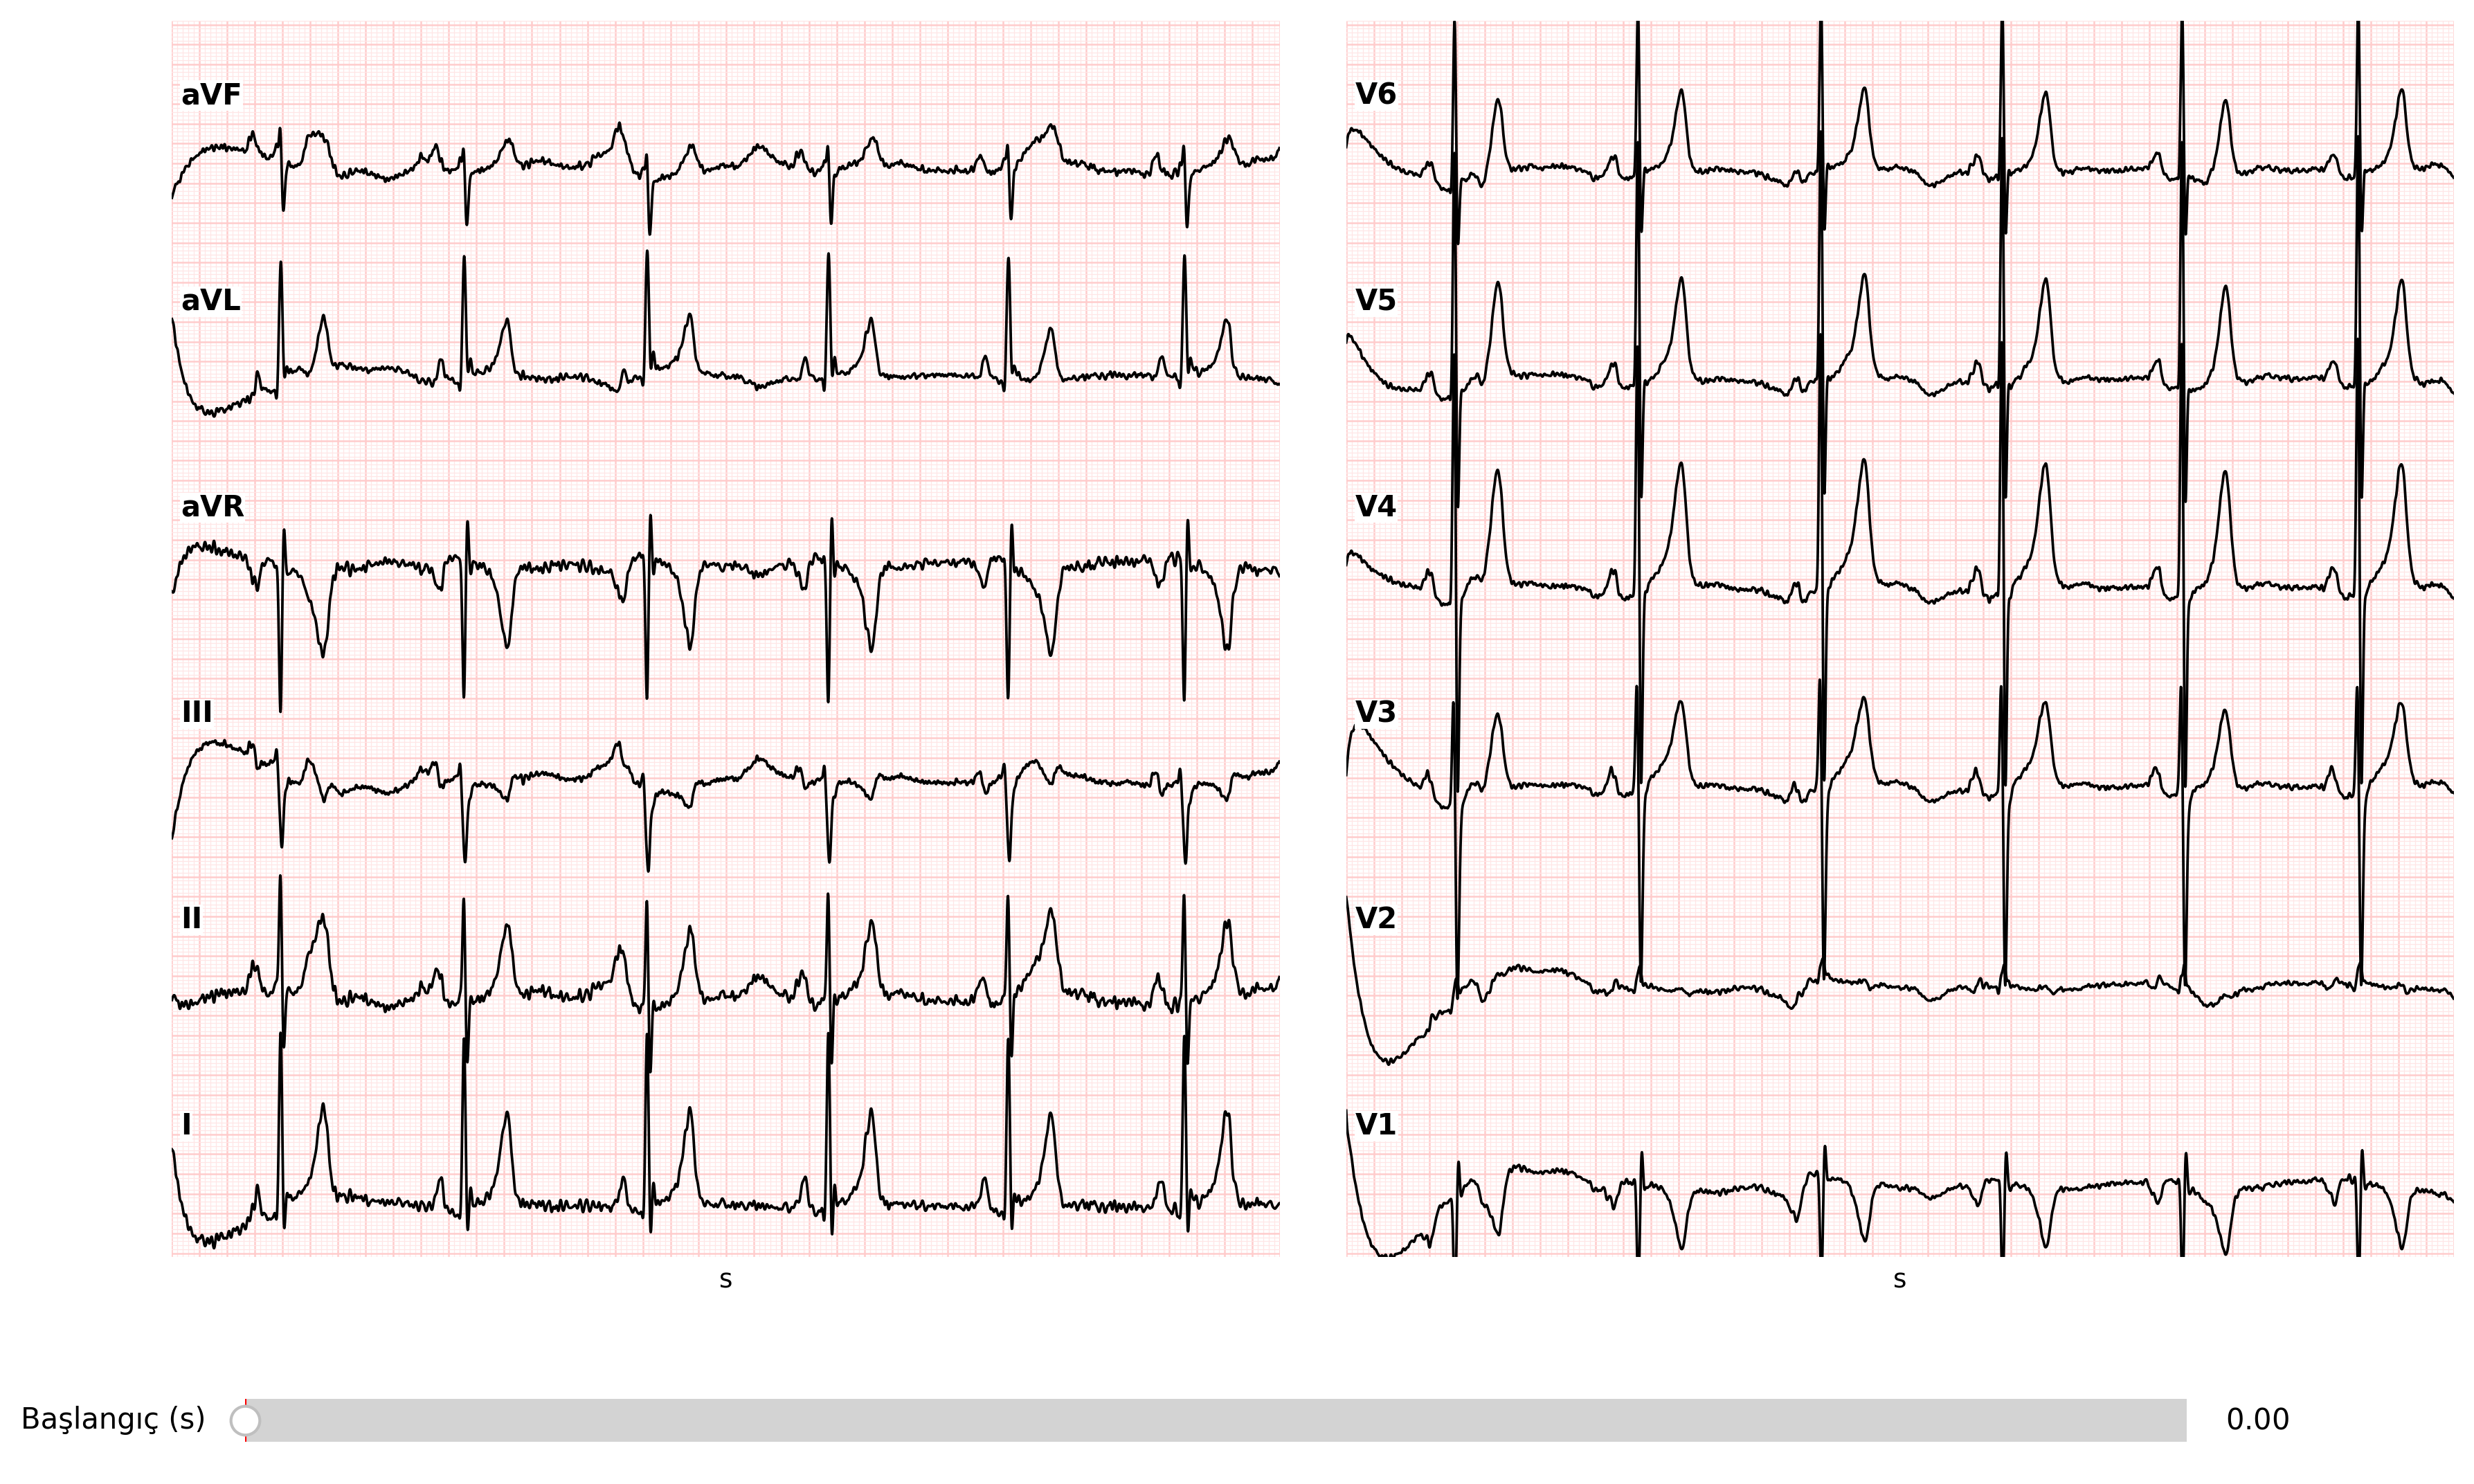

In [ ]:
# -*- coding: utf-8 -*-
# 12-lead ECG → 2 büyük grid (sol 6, sağ 6) • KAYDIRMALI 8 sn pencere
# - Tüm veri okunur, ekranda sadece 8 sn'lik pencere gösterilir ve kaydırılır
# - Grid penceresi sabit: 8 sn genişliğinde
# pip install numpy scipy matplotlib

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.widgets import Slider, Button
from scipy.signal import butter, filtfilt, iirnotch
from datetime import datetime

# --------- AYARLAR ---------
TXT_PATH = "/content/01_Aug_2024_Aziz_Soydoğan_PRE_PTCA.ekg.txt"
OUT_PATH_PNG = "ecg_12lead_two_big_grids.png"  # 'S' ile aktif pencereyi kaydederken taban ad
FS = 500
WINDOW_SEC = 8.0

LEADS = ["I","II","III","aVR","aVL","aVF","V1","V2","V3","V4","V5","V6"]

# Kağıt standartları
PAPER_SPEED_MM_S   = 25   # 25 mm/s
SENSITIVITY_MM_MV  = 10   # 10 mm/mV

# Filtreler
APPLY_FILTERS = True
BAND_LOW_HZ   = 0.5
BAND_HIGH_HZ  = 35.0
NOTCH_HZ      = 50
NOTCH_Q       = 30.0

# ADC → mV
ADC_uV_PER_COUNT = None        # µV/count biliniyorsa gir
AUTO_GAIN_P95_MV = 1.5         # 95. persentil ~1.5 mV olacak şekilde normalize

# Sayfa
DPI = 300
FIGSIZE_INCH = (11.69, 8.27)   # A4 yatay
# ---------------------------

def load_txt(path):
    try:
        arr = np.genfromtxt(path, delimiter=",", dtype=float)
    except Exception:
        arr = np.genfromtxt(path, dtype=float)
    if arr.ndim == 1:
        arr = arr.reshape(-1, 12)
    if arr.shape[1] != 12:
        raise ValueError(f"12 kolon bekleniyordu; dosyada {arr.shape[1]} kolon var.")
    return arr

def bandpass(sig, fs, low=0.5, high=35.0, order=3):
    b, a = butter(order, [low/(fs/2), high/(fs/2)], btype="band")
    return filtfilt(b, a, sig)

def notch(sig, fs, f0=50.0, Q=30.0):
    b, a = iirnotch(f0/(fs/2), Q)
    return filtfilt(b, a, sig)

def to_mV(x, adc_uV_per_count=None, target_p95_mv=1.5):
    if adc_uV_per_count is not None:
        return x * (adc_uV_per_count / 1000.0)
    scale = np.nanpercentile(np.abs(x), 95)
    if not np.isfinite(scale) or scale == 0:
        scale = 1.0
    return (x / scale) * target_p95_mv

def draw_full_grid(ax, duration_s, y_min_mv, y_max_mv, speed_mm_s=25, sens_mm_mv=10):
    """Panelin tamamına tek parça ECG grid çizer (burada duration_s = pencere süresi = 8 sn)."""
    small_t = 0.04 * (speed_mm_s/25.0)
    big_t   = 0.20 * (speed_mm_s/25.0)
    small_y = 0.10 * (10.0/sens_mm_mv)
    big_y   = 0.50 * (10.0/sens_mm_mv)

    t = 0.0
    while t <= duration_s + 1e-9:
        is_big = (abs((t/big_t) - round(t/big_t)) < 1e-9)
        ax.axvline(t, color="#ffcccc" if is_big else "#ffe6e6",
                   lw=0.6 if is_big else 0.3, zorder=0)
        t += small_t

    y = y_min_mv - (y_min_mv % small_y)
    while y <= y_max_mv + 1e-9:
        is_big = (abs((y/big_y) - round(y/big_y)) < 1e-9)
        ax.axhline(y, color="#ffcccc" if is_big else "#ffe6e6",
                   lw=0.6 if is_big else 0.3, zorder=0)
        y += small_y

    ax.set_xlim(0, duration_s)
    ax.set_ylim(y_min_mv, y_max_mv)
    ax.set_yticks([])
    ax.set_xticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)

def render_two_big_grids_interactive(sig_mv, fs, window_sec, out_png_base, lead_labels=None):
    if lead_labels is None:
        lead_labels = LEADS
    n, ch = sig_mv.shape
    assert ch == 12, "12 kanal bekleniyor."
    total_duration_s = n / fs
    win_samples = int(window_sec * fs)

    # Görsel y-ölçeği
    p95 = np.nanpercentile(np.abs(sig_mv), 95)
    mv_range = 2.0
    while p95 > 0.9*mv_range and mv_range < 5.0:
        mv_range += 0.5

    gap = mv_range * 2.6
    top_margin = mv_range * 0.8
    bottom_margin = mv_range * 0.8
    y_min = -bottom_margin
    y_max = gap*5 + mv_range + top_margin  # 6 lead → 0..5

    # Sıralama
    left_order  = ["I","II","III","aVR","aVL","aVF"]
    right_order = ["V1","V2","V3","V4","V5","V6"]

    # --- FIGÜR ---
    fig = plt.figure(figsize=FIGSIZE_INCH, dpi=DPI)
    # Üstte sinyal panelleri, altta slider için boşluk bırak
    gs = GridSpec(1, 2, figure=fig,
                  top=0.92, bottom=0.20, left=0.05, right=0.99,
                  wspace=0.06)

    # SOL PANEL
    axL = fig.add_subplot(gs[0, 0])
    draw_full_grid(axL, window_sec, y_min, y_max, PAPER_SPEED_MM_S, SENSITIVITY_MM_MV)

    # SAĞ PANEL
    axR = fig.add_subplot(gs[0, 1])
    draw_full_grid(axR, window_sec, y_min, y_max, PAPER_SPEED_MM_MV := PAPER_SPEED_MM_S, SENSITIVITY_MM_MV)

    # Lead çizgilerini oluştur (boş veri, sonra doldurulacak)
    lineL = {}
    for i, lead in enumerate(left_order):
        offset = i * gap
        ln, = axL.plot([], [], color="black", lw=0.9, zorder=5)
        lineL[lead] = (ln, offset)
        axL.text(0.008*window_sec, offset + mv_range*0.75, lead,
                 fontsize=10, weight="bold",
                 bbox=dict(facecolor="white", edgecolor="none", pad=0.2), zorder=6)

    lineR = {}
    for i, lead in enumerate(right_order):
        offset = i * gap
        ln, = axR.plot([], [], color="black", lw=0.9, zorder=5)
        lineR[lead] = (ln, offset)
        axR.text(0.008*window_sec, offset + mv_range*0.75, lead,
                 fontsize=10, weight="bold",
                 bbox=dict(facecolor="white", edgecolor="none", pad=0.2), zorder=6)

    axL.set_xlabel("s", fontsize=9, labelpad=4)
    axR.set_xlabel("s", fontsize=9, labelpad=4)

    # --- SLIDER alanı ---
    ax_slide = plt.axes([0.08, 0.08, 0.80, 0.05])  # left, bottom, width, height
    max_start = max(0.0, total_duration_s - window_sec)
    slider = Slider(ax_slide, 'Başlangıç (s)', 0.0, max_start, valinit=0.0, valstep=0.1)

    # --- GÜNCELLEME FONKSİYONU ---
    def set_window(t0):
        # Güvenli kenar
        t0 = float(np.clip(t0, 0.0, max_start))
        s = int(round(t0 * fs))
        e = min(n, s + win_samples)
        # Ekran zamanını 0'dan başlat (grid hizası temiz olsun)
        t_win = (np.arange(s, e) / fs) - (s / fs)

        # Sol panel lead'leri doldur
        for lead in left_order:
            idx = lead_labels.index(lead)
            ln, offset = lineL[lead]
            y = sig_mv[s:e, idx] + offset
            ln.set_data(t_win, y)

        # Sağ panel lead'leri doldur
        for lead in right_order:
            idx = lead_labels.index(lead)
            ln, offset = lineR[lead]
            y = sig_mv[s:e, idx] + offset
            ln.set_data(t_win, y)

        fig.canvas.draw_idle()
        return t0, s, e

    # Slider callback
    def on_slide(val):
        set_window(val)
    slider.on_changed(on_slide)

    # --- KISAYOLLAR ---
    step_small = 0.5   # sn
    step_page  = 1.0   # sn

    def on_key(event):
        if event.key in ["right", "left", "pagedown", "pageup", "s"]:
            cur = slider.val
            if event.key == "right":
                slider.set_val(min(max_start, cur + step_small))
            elif event.key == "left":
                slider.set_val(max(0.0, cur - step_small))
            elif event.key == "pagedown":
                slider.set_val(min(max_start, cur + step_page))
            elif event.key == "pageup":
                slider.set_val(max(0.0, cur - step_page))
            elif event.key == "s":
                # Aktif pencereyi PNG kaydet
                t0, s, e = set_window(slider.val)
                stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
                out_name = f"{os.path.splitext(out_png_base)[0]}_win_{t0:.2f}s_{stamp}.png"
                fig.savefig(out_name, dpi=DPI)
                print(f"✓ Pencere kaydedildi: {out_name}")

    fig.canvas.mpl_connect("key_press_event", on_key)

    # Başlangıç çizimi
    set_window(0.0)
    plt.show()

def main():
    raw = load_txt(TXT_PATH).astype(float)
    x = raw.copy()
    if APPLY_FILTERS:
        for k in range(x.shape[1]):
            x[:, k] = bandpass(x[:, k], FS, BAND_LOW_HZ, BAND_HIGH_HZ, order=3)
            x[:, k] = notch(x[:, k], FS, f0=NOTCH_HZ, Q=NOTCH_Q)
    sig_mv = to_mV(x, ADC_uV_PER_COUNT, target_p95_mv=AUTO_GAIN_P95_MV)

    render_two_big_grids_interactive(
        sig_mv=sig_mv,
        fs=FS,
        window_sec=WINDOW_SEC,
        out_png_base=OUT_PATH_PNG,
        lead_labels=LEADS
    )

if __name__ == "__main__":
    main()


In [ ]:
# Colab: tek seferlik kurulum
# !pip install numpy scipy plotly

import numpy as np
from scipy.signal import butter, filtfilt, iirnotch
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --------- AYARLAR ---------
TXT_PATH = "/content/01_Aug_2024_Aziz_Soydoğan_PRE_PTCA.ekg.txt"
FS = 500
WINDOW_SEC = 8.0

LEADS = ["I","II","III","aVR","aVL","aVF","V1","V2","V3","V4","V5","V6"]

# Kağıt benzeri ölçek
PAPER_SPEED_MM_S   = 25   # sadece grid ölçeği için kullanacağız (görsel amaçlı)
SENSITIVITY_MM_MV  = 10

# Filtreler
APPLY_FILTERS = True
BAND_LOW_HZ   = 0.5
BAND_HIGH_HZ  = 35.0
NOTCH_HZ      = 50
NOTCH_Q       = 30.0

ADC_uV_PER_COUNT = None
AUTO_GAIN_P95_MV = 1.5

def load_txt(path):
    try:
        arr = np.genfromtxt(path, delimiter=",", dtype=float)
    except Exception:
        arr = np.genfromtxt(path, dtype=float)
    if arr.ndim == 1:
        arr = arr.reshape(-1, 12)
    if arr.shape[1] != 12:
        raise ValueError(f"12 kolon bekleniyordu; dosyada {arr.shape[1]} kolon var.")
    return arr

def bandpass(sig, fs, low=0.5, high=35.0, order=3):
    b, a = butter(order, [low/(fs/2), high/(fs/2)], btype="band")
    return filtfilt(b, a, sig)

def notch(sig, fs, f0=50.0, Q=30.0):
    b, a = iirnotch(f0/(fs/2), Q)
    return filtfilt(b, a, sig)

def to_mV(x, adc_uV_per_count=None, target_p95_mv=1.5):
    if adc_uV_per_count is not None:
        return x * (adc_uV_per_count / 1000.0)
    scale = np.nanpercentile(np.abs(x), 95)
    if not np.isfinite(scale) or scale == 0:
        scale = 1.0
    return (x / scale) * target_p95_mv

# --- Veri ---
raw = load_txt(TXT_PATH).astype(float)
x = raw.copy()
if APPLY_FILTERS:
    for k in range(x.shape[1]):
        x[:, k] = bandpass(x[:, k], FS, BAND_LOW_HZ, BAND_HIGH_HZ, order=3)
        x[:, k] = notch(x[:, k], FS, f0=NOTCH_HZ, Q=NOTCH_Q)
sig_mv = to_mV(x, ADC_uV_PER_COUNT, target_p95_mv=AUTO_GAIN_P95_MV)

N = sig_mv.shape[0]
t = np.arange(N)/FS
total_duration_s = N/FS

# Görsel y-ölçeği ve ofsetler
p95 = np.nanpercentile(np.abs(sig_mv), 95)
mv_range = 2.0
while p95 > 0.9*mv_range and mv_range < 5.0:
    mv_range += 0.5
gap = mv_range * 2.6

left_order  = ["I","II","III","aVR","aVL","aVF"]
right_order = ["V1","V2","V3","V4","V5","V6"]

# --- Şekil: 2 sütun (sol: 6 lead, sağ: 6 lead)
fig = make_subplots(rows=6, cols=2, shared_xaxes=True, horizontal_spacing=0.06)

# Sol sütun
for i, lead in enumerate(left_order, start=1):
    idx = LEADS.index(lead)
    fig.add_trace(
        go.Scatter(x=t, y=sig_mv[:, idx] + (i-1)*gap,
                   mode="lines", line=dict(width=1),
                   name=lead, showlegend=False),
        row=i, col=1
    )
    fig.add_annotation(xref=f"x{i}", yref=f"y{i}",
                       x=t[0] + 0.01*total_duration_s, y=(i-1)*gap + 0.75*mv_range,
                       text=f"<b>{lead}</b>", showarrow=False, font=dict(size=10),
                       row=i, col=1)

# Sağ sütun
for i, lead in enumerate(right_order, start=1):
    idx = LEADS.index(lead)
    fig.add_trace(
        go.Scatter(x=t, y=sig_mv[:, idx] + (i-1)*gap,
                   mode="lines", line=dict(width=1),
                   name=lead, showlegend=False),
        row=i, col=2
    )
    fig.add_annotation(xref=f"x{i+6}", yref=f"y{i+6}",
                       x=t[0] + 0.01*total_duration_s, y=(i-1)*gap + 0.75*mv_range,
                       text=f"<b>{lead}</b>", showarrow=False, font=dict(size=10),
                       row=i, col=2)

# Eksen düzeni
for r in range(1, 7):
    for c in (1, 2):
        fig.update_yaxes(visible=False, row=r, col=c)

# Başlangıçta 0–8 sn göster
x0, x1 = 0.0, min(WINDOW_SEC, total_duration_s)
fig.update_xaxes(range=[x0, x1])

# Altta rangeslider: bunu sağa-sola çekerek 8 sn’lik pencereyi kaydır
# (Range genişliğini mouse ile de değiştirebilirsin; 8 sn sabit kalsın istiyorsan elle dokunma)
fig.update_xaxes(
    rangeslider=dict(visible=True),
    row=6, col=1
)
fig.update_xaxes(
    rangeslider=dict(visible=True),
    row=6, col=2
)

# Tüm x-ekseni stilleri (saniye)
for r in range(1, 7):
    for c in (1, 2):
        fig.update_xaxes(title_text="s", row=r, col=c)

fig.update_layout(
    height=900, width=1400,
    margin=dict(l=20, r=20, t=40, b=40),
    title="12-Lead ECG • 2 Panel (Sol 6 / Sağ 6) • Kaydırılabilir"
)

fig.show()


Output hidden; open in https://colab.research.google.com to view.